# 3 · Kelly criterion, fractional Kelly and leverage constraints
Kelly sizing maximises long-run log-growth, but it is extremely sensitive to expected-return estimates. We study
* the growth-vs-leverage curve: why over-betting is catastrophic,
* half-Kelly and leverage caps as practical risk controls,
* a Monte Carlo of terminal wealth under different Kelly fractions.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
prices = pd.read_csv("../data/prices.csv", index_col=0, parse_dates=True)   # refresh: python scripts/fetch_prices.py
bench = prices.pop("SPY")
rets = np.log(prices).diff().dropna()
RF = 0.025  # average T-bill rate over the sample (approx.)
from portopt import covariance, kelly

In [2]:
cov = covariance.ledoit_wolf(rets)
# shrink historical means 50% towards their cross-sectional average: a simple guard against estimation error
mu_raw = rets.mean() * 252
mu = 0.5 * mu_raw + 0.5 * mu_raw.mean()
k_full = kelly.kelly_weights(mu, cov, RF)
tbl = pd.DataFrame({"full Kelly": k_full, "half Kelly": 0.5 * k_full,
                    "long-only, 1.5x cap": kelly.kelly_weights(mu, cov, RF, long_only=True, max_leverage=1.5)})
print("Gross leverage:", tbl.abs().sum().round(2).to_dict())
tbl.round(3)

Gross leverage: {'full Kelly': 9.7, 'half Kelly': 4.85, 'long-only, 1.5x cap': 1.5}


,full Kelly,half Kelly,"long-only, 1.5x cap"
AAPL,0.532,0.266,0.102
BAC,-0.584,-0.292,0.000
CVX,-0.773,-0.387,0.000
GS,-0.173,-0.086,0.000
JNJ,2.382,1.191,0.455
JPM,1.220,0.610,0.233
KO,1.242,0.621,0.237
MSFT,0.467,0.233,0.089
NVDA,0.867,0.434,0.166
PFE,-0.317,-0.159,0.000


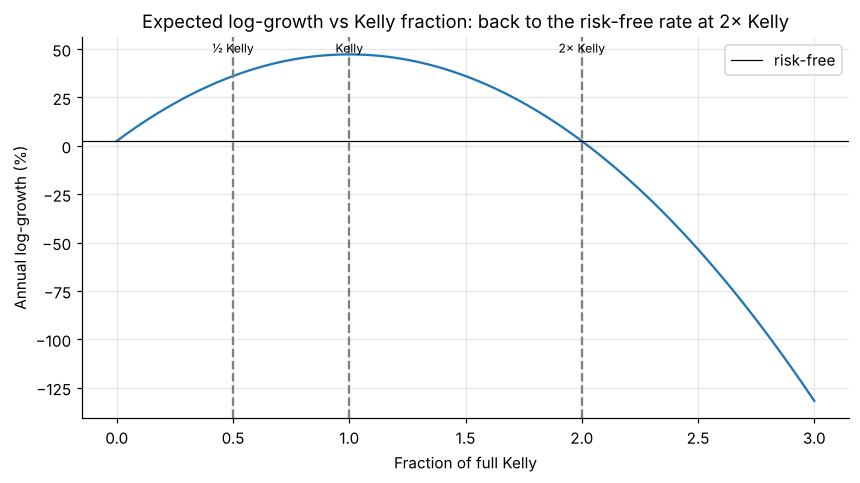

In [3]:
fractions = np.linspace(0, 3, 121)
growth = [kelly.expected_growth(f * k_full, mu, cov, RF) for f in fractions]
plt.plot(fractions, np.array(growth) * 100)
for f, lbl in [(0.5, "½ Kelly"), (1, "Kelly"), (2, "2× Kelly")]:
    plt.axvline(f, ls="--", color="grey"); plt.text(f, max(growth) * 100 * 1.02, lbl, ha="center", fontsize=8)
plt.axhline(RF * 100, color="k", lw=0.8, label="risk-free")
plt.title("Expected log-growth vs Kelly fraction: back to the risk-free rate at 2× Kelly")
plt.xlabel("Fraction of full Kelly"); plt.ylabel("Annual log-growth (%)"); plt.legend()
plt.savefig(IMG / "kelly_growth_curve.png", bbox_inches="tight"); plt.show()

## Monte Carlo of terminal wealth (10 years, model world)

In [4]:
rng = np.random.default_rng(1)
years, n_sims = 10, 4000
L = np.linalg.cholesky(cov.values / 252)
sims = {}
for f in (0.25, 0.5, 1.0, 2.0):
    w = (f * k_full).values
    daily = (mu.values / 252) - 0.5 * np.diag(cov.values) / 252
    log_w = np.zeros(n_sims)
    for _ in range(years):  # simulate a year at a time to limit memory
        z = rng.standard_normal((252, n_sims, len(w)))
        asset = np.exp(daily + z @ L.T) - 1                   # simple daily returns
        port = asset @ w + (1 - w.sum()) * RF / 252
        log_w += np.log1p(np.maximum(port, -0.999)).sum(axis=0)
    sims[f"{f}× Kelly"] = np.exp(log_w)
res = pd.DataFrame(sims)
summary = pd.DataFrame({"median wealth": res.median(), "5th pct": res.quantile(0.05),
                        "P(wealth < 1)": (res < 1).mean(), "P(lose 50%+)": (res < 0.5).mean()})
summary.round(3)

,median wealth,5th pct,P(wealth < 1),P(lose 50%+)
0.25× Kelly,9.342,2.716,0.001,0.000
0.5× Kelly,38.125,3.492,0.008,0.003
1.0× Kelly,110.550,0.803,0.060,0.034
2.0× Kelly,0.961,0.000,0.503,0.454


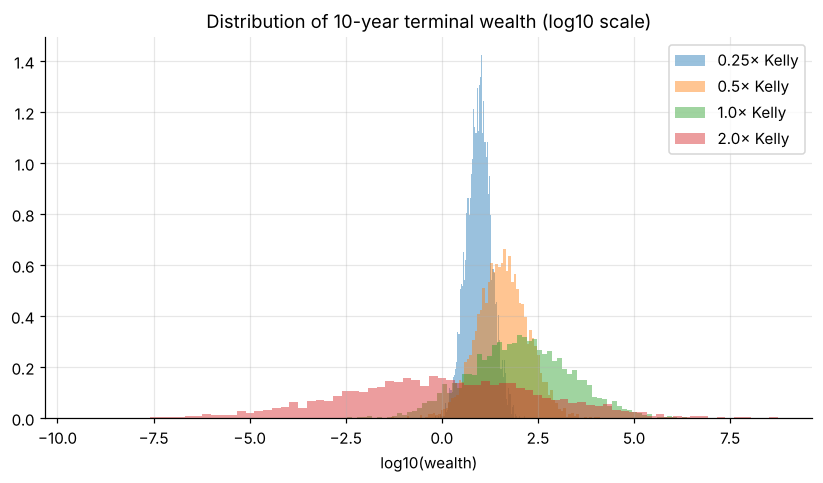

In [5]:
for c in res: plt.hist(np.log10(res[c]), bins=80, alpha=0.45, label=c, density=True)
plt.title("Distribution of 10-year terminal wealth (log10 scale)"); plt.xlabel("log10(wealth)"); plt.legend()
plt.savefig(IMG / "kelly_terminal_wealth.png", bbox_inches="tight"); plt.show()

**Takeaway:** full Kelly has the highest median wealth but a wide left tail. Half Kelly gives up a little growth for a large drop in drawdown risk. Beyond 2× Kelly, expected growth turns negative even though each bet has positive expected return. Because estimated means are noisy, practitioners size at a fraction of Kelly and cap gross leverage.